# **Project Report - 12**

# **Bachelor of Computer Applications (BCA)**

#**Semester – V**

####**Sub**: Deep Learning ####

####**Topic:**  Understanding Convolution and Pooling ####


####**Submitted By** ####

####**Name:** Pragathi BR ####

####**Reg no:** 2411021240037 ####

####**Date of Submission:** 25/10/2026 ####

####**Faculty Name:** Nagasri. P ####

## **Introduction**

Convolution and pooling are two important operations used in Convolutional Neural Networks (CNNs). They help a model identify useful features from images.

Convolution applies filters or kernels to an image to detect features such as edges, lines, textures, and patterns. Different filters produce different feature maps.

Pooling reduces the dimensions of feature maps while retaining important information. It helps reduce computational cost and makes image processing more efficient.

In this project, Python is used to load a sample image, apply different convolution filters, perform max pooling and average pooling, and visualize the results.



## **Objectives**

1. To load and display a sample image using Python.
2. To understand the concept of convolution and convolution filters.
3. To apply different filters to an image and generate feature maps.
4. To perform max pooling and average pooling operations.
5. To visualize and compare the original image, filtered images, and pooled images.
6. To understand how convolution and pooling are used in CNNs for feature extraction and dimensionality reduction.



## **Theory**

### **1. Convolution**

Convolution is an operation in which a small matrix called a filter or kernel moves across an image. At each position, the values of the filter are multiplied by the corresponding image values and added together.

The output is called a feature map. Different filters can detect different image features, such as edges, horizontal lines, vertical lines, and textures.

### **2. Convolution Filters**

- Identity filter: Retains the original image pattern.
- Edge detection filter: Highlights boundaries and edges.
- Blur filter: Smooths the image and reduces small details.
- Sharpen filter: Enhances edges and fine details.

### **3. Feature Map**

A feature map is the output obtained after applying a convolution filter to an image. It highlights the patterns detected by that filter.

### **4. Pooling**

Pooling reduces the spatial dimensions of a feature map by summarizing values within small regions, such as 2 × 2 blocks.

Max pooling selects the maximum value from each region.

Average pooling calculates the average value of each region.

### **5. Importance of Convolution and Pooling**

Convolution helps extract useful image features, while pooling reduces feature-map dimensions. Together, these operations help CNNs process images efficiently.



## **Task 1: Load a Sample Image**

The first task is to load a sample image using Python. The required libraries are NumPy for numerical operations, Matplotlib for visualization, and scikit-image for the sample image. SciPy is used to perform convolution operations.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy.signal import convolve2d

print("All libraries imported successfully!")


All libraries imported successfully!



### **Loading the Sample Image**

In this step, the built-in camera image from the scikit-image library is loaded. It is a grayscale image, which makes it suitable for demonstrating convolution and pooling without needing additional color-channel processing.

The image is displayed using Matplotlib.


Image shape: (512, 512)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


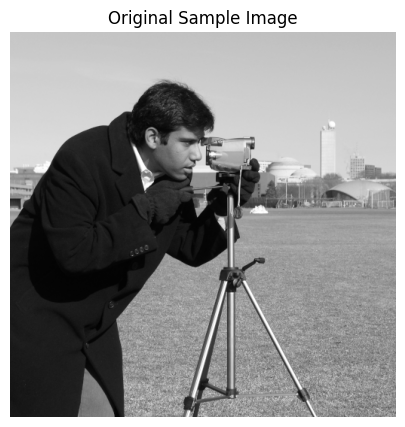

In [2]:

# Load the sample grayscale image
image = data.camera()

# Display image information
print("Image shape:", image.shape)
print("Image data type:", image.dtype)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

# Display the original image
plt.figure(figsize=(7, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Sample Image")
plt.axis("off")
plt.show()



## **Task 2: Apply Convolution Filters and Pooling Operations**

### **Applying Convolution Filters**

A convolution filter is a small matrix that moves across an image to detect specific patterns.

In this experiment, four filters are used:

1. Edge detection filter to highlight boundaries.
2. Horizontal edge filter to emphasize horizontal intensity changes.
3. Blur filter to smooth the image.
4. Sharpen filter to enhance image details.

The output produced by each filter is called a feature map.


In [10]:

# Edge detection filter
edge_filter = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=float)

# Horizontal edge filter
horizontal_filter = np.array([
    [-1, -1, -1],
    [ 2,  2,  2],
    [-1, -1, -1]
], dtype=float)

# Blur filter
blur_filter = np.ones((3, 3), dtype=float) / 9

# Sharpen filter
sharpen_filter = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=float)

print("Convolution filters defined successfully.")


Convolution filters defined successfully.



### **Performing Convolution**

Each convolution filter is applied to the original image. The 'same' mode preserves the input image dimensions.

The edge feature maps can contain positive and negative values. Their absolute values are used during visualization to display the strength of detected edges.


In [11]:

# Convert image to floating-point values
image_float = image.astype(float)

# Apply convolution filters
edge_map = convolve2d(
    image_float, edge_filter,
    mode="same", boundary="symm"
)

horizontal_map = convolve2d(
    image_float, horizontal_filter,
    mode="same", boundary="symm"
)

blur_map = convolve2d(
    image_float, blur_filter,
    mode="same", boundary="symm"
)

sharpen_map = convolve2d(
    image_float, sharpen_filter,
    mode="same", boundary="symm"
)

print("Convolution operations completed.")
print("Edge feature map shape:", edge_map.shape)
print("Horizontal feature map shape:", horizontal_map.shape)
print("Blur feature map shape:", blur_map.shape)
print("Sharpen feature map shape:", sharpen_map.shape)


Convolution operations completed.
Edge feature map shape: (512, 512)
Horizontal feature map shape: (512, 512)
Blur feature map shape: (512, 512)
Sharpen feature map shape: (512, 512)



### **Pooling Operations**

Pooling reduces the dimensions of a feature map while retaining useful information.

Max pooling selects the maximum value from each 2 × 2 region. Average pooling calculates the mean of the values in each 2 × 2 region.

A stride of 2 moves the pooling window two pixels at a time, reducing the height and width of the feature map by half.


In [12]:

def max_pooling(image, pool_size=2, stride=2):
    height, width = image.shape

    out_height = (height - pool_size) // stride + 1
    out_width = (width - pool_size) // stride + 1

    pooled = np.zeros((out_height, out_width), dtype=float)

    for i in range(out_height):
        for j in range(out_width):
            region = image[
                i * stride:i * stride + pool_size,
                j * stride:j * stride + pool_size
            ]
            pooled[i, j] = np.max(region)

    return pooled


def average_pooling(image, pool_size=2, stride=2):
    height, width = image.shape

    out_height = (height - pool_size) // stride + 1
    out_width = (width - pool_size) // stride + 1

    pooled = np.zeros((out_height, out_width), dtype=float)

    for i in range(out_height):
        for j in range(out_width):
            region = image[
                i * stride:i * stride + pool_size,
                j * stride:j * stride + pool_size
            ]
            pooled[i, j] = np.mean(region)

    return pooled


print("Pooling functions defined successfully.")


Pooling functions defined successfully.



### **Applying Max Pooling and Average Pooling**

The pooling functions are applied to the absolute edge feature map generated by convolution.

Max pooling preserves the strongest edge response in each region. Average pooling calculates the average edge response in each region.

The resulting feature maps are smaller than the original image.


In [13]:

# Apply pooling to the edge feature map
edge_magnitude = np.abs(edge_map)

max_pooled = max_pooling(
    edge_magnitude, pool_size=2, stride=2
)

average_pooled = average_pooling(
    edge_magnitude, pool_size=2, stride=2
)

print("Original image shape:", image.shape)
print("Edge feature map shape:", edge_map.shape)
print("Max pooled shape:", max_pooled.shape)
print("Average pooled shape:", average_pooled.shape)


Original image shape: (512, 512)
Edge feature map shape: (512, 512)
Max pooled shape: (256, 256)
Average pooled shape: (256, 256)



## **Task 3: Visualize and Compare the Original Image and Generated Feature Maps**

In this task, the original image is compared with the feature maps generated by different convolution filters.

The edge detection filter highlights boundaries, the horizontal edge filter emphasizes horizontal intensity changes, the blur filter smooths the image, and the sharpen filter enhances details.

Visualizing these results helps us understand how different convolution filters extract different features from the same image.


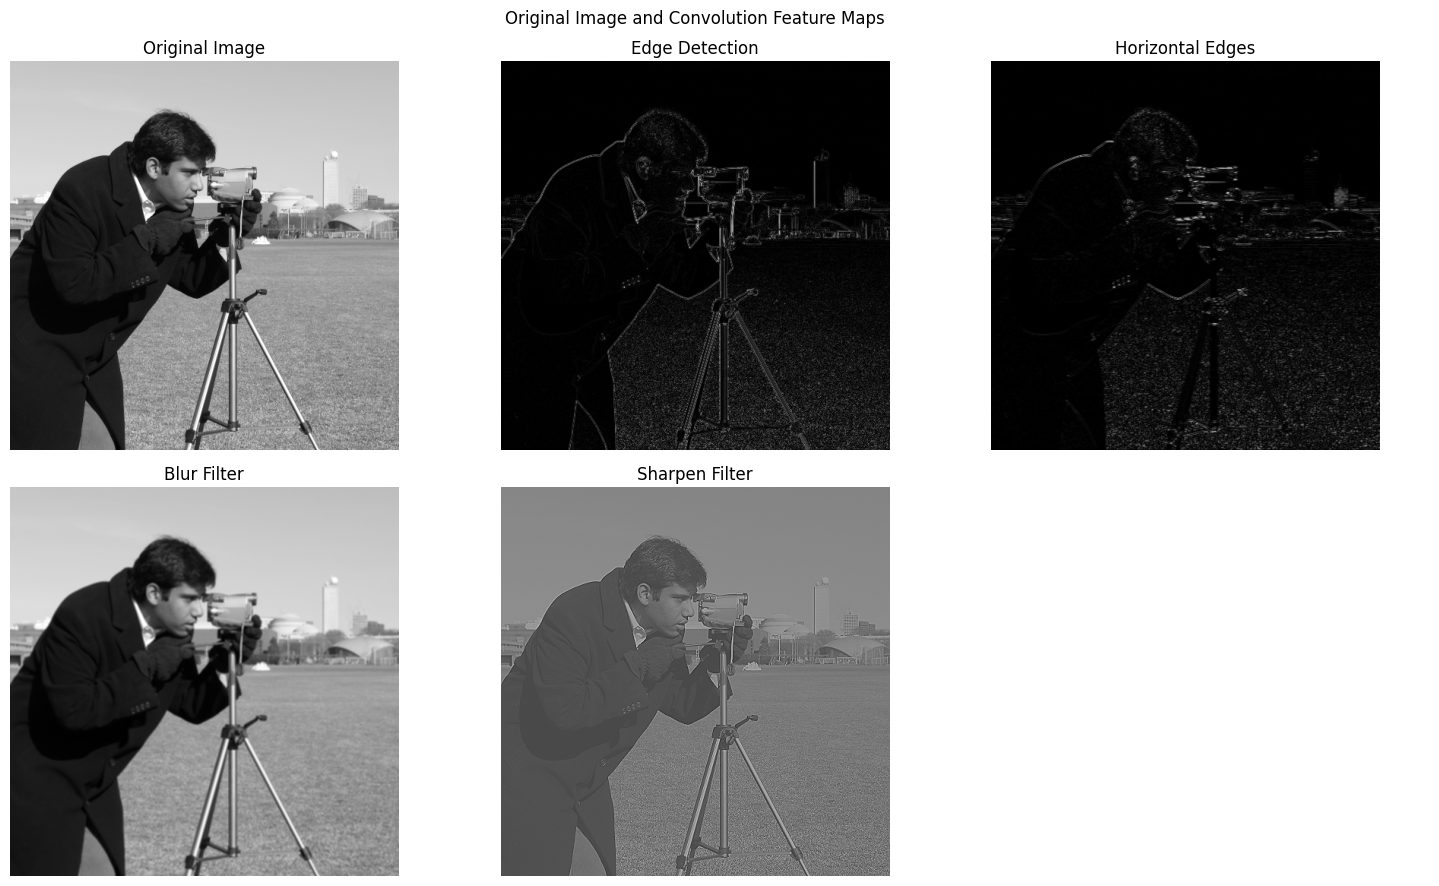

In [14]:

# Compare the original image and convolution feature maps
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

images_to_show = [
    (image, "Original Image"),
    (np.abs(edge_map), "Edge Detection"),
    (np.abs(horizontal_map), "Horizontal Edges"),
    (blur_map, "Blur Filter"),
    (sharpen_map, "Sharpen Filter")
]

for ax, (img, title) in zip(axes.flat, images_to_show):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

# Hide the unused subplot
axes.flat[5].axis("off")

plt.suptitle("Original Image and Convolution Feature Maps")
plt.tight_layout()
plt.show()



### **Comparison of Convolution and Pooling Results**

The original image, edge feature map, max-pooled image, and average-pooled image are displayed together.

Max pooling preserves the strongest local responses. Average pooling smooths the responses by calculating their mean. Both operations reduce the spatial dimensions of the feature map from 512 × 512 to 256 × 256.


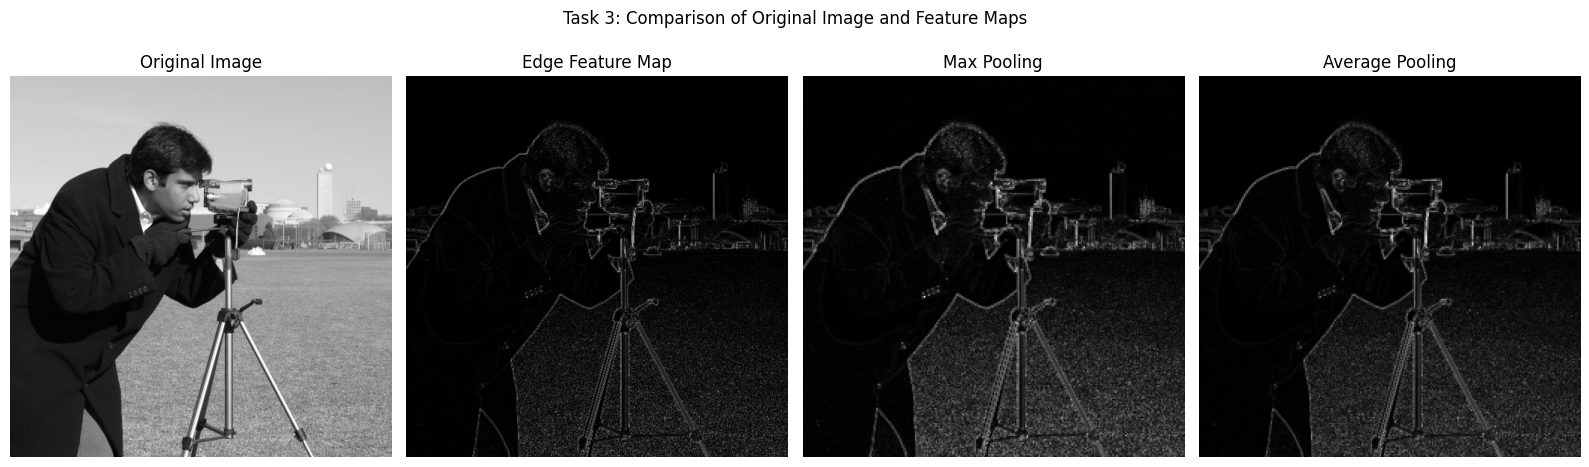

In [15]:

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(edge_magnitude, cmap="gray")
axes[1].set_title("Edge Feature Map")

axes[2].imshow(max_pooled, cmap="gray")
axes[2].set_title("Max Pooling")

axes[3].imshow(average_pooled, cmap="gray")
axes[3].set_title("Average Pooling")

for ax in axes:
    ax.axis("off")

plt.suptitle("Task 3: Comparison of Original Image and Feature Maps")
plt.tight_layout()
plt.show()



### **Comparison of Image Dimensions**

Convolution with the 'same' mode preserves the spatial dimensions of the input image. Pooling with a 2 × 2 window and stride of 2 reduces the height and width by half.

Therefore, the number of spatial values decreases from 262,144 to 65,536, representing a 75% reduction.


In [16]:

original_pixels = image.shape[0] * image.shape[1]
pooled_pixels = max_pooled.shape[0] * max_pooled.shape[1]

print("Original image dimensions:", image.shape)
print("Convolution output dimensions:", edge_map.shape)
print("Max pooling dimensions:", max_pooled.shape)
print("Average pooling dimensions:", average_pooled.shape)

print("\nOriginal number of pixels:", original_pixels)
print("Pooled number of values:", pooled_pixels)

reduction = (1 - pooled_pixels / original_pixels) * 100
print("Reduction in spatial values:", round(reduction, 2), "%")


Original image dimensions: (512, 512)
Convolution output dimensions: (512, 512)
Max pooling dimensions: (256, 256)
Average pooling dimensions: (256, 256)

Original number of pixels: 262144
Pooled number of values: 65536
Reduction in spatial values: 75.0 %



## **Observations**

1. The sample grayscale image was successfully loaded using Python.
2. The edge detection filter highlighted boundaries and changes in image intensity.
3. The horizontal edge filter emphasized horizontal intensity changes.
4. The blur filter smoothed the image and reduced fine details.
5. The sharpen filter enhanced image edges and details.
6. Convolution generated different feature maps from the same input image.
7. Max pooling preserved the maximum response in each 2 × 2 region.
8. Average pooling calculated the average response in each 2 × 2 region.
9. Both pooling operations reduced the feature map dimensions from 512 × 512 to 256 × 256.
10. Pooling reduced the number of spatial values by 75%.
11. The visual comparison demonstrated the importance of convolution and pooling in CNNs.



## **Result**

The project was successfully implemented using Python. A sample image was loaded, and different convolution filters were applied to generate feature maps. Max pooling and average pooling were then performed on the edge feature map.

The original image, convolution outputs, and pooled images were visualized and compared. The results demonstrated that convolution extracts image features while pooling reduces spatial dimensions and preserves useful information.



## **Conclusion**

This project provided a practical understanding of convolution and pooling operations used in Convolutional Neural Networks (CNNs).

Convolution filters extracted different image features, including edges, horizontal patterns, smooth regions, and fine details. Max pooling retained the strongest responses, whereas average pooling calculated average responses from local regions.

Both pooling methods reduced the feature map dimensions from 512 × 512 to 256 × 256, reducing the number of spatial values by 75%.

Thus, convolution and pooling are important operations in CNNs because they help extract meaningful image features and reduce computational requirements during image processing.
